In [3]:
!pip install osmnx rasterio matplotlib networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.4/104.4 kB 3.7 MB/s eta 0:00:00


 1. CONFIGURATION & PATH SETUP                              
 -> Path DEMNAS : /content/drive/MyDrive/Kuliah/Proyek ASA/04_Notebook/dataset/DEMNAS_1409-22_v1.0.tif
 -> Path CSV    : /content/drive/MyDrive/Kuliah/Proyek ASA/04_Notebook/dataset/chart_data.csv
----------------------------------------------------------------------
 2. SPATIAL GRAPH ACQUISITION (OSMNX SCRAPING)              
 Mengunduh topologi jaringan jalan raya untuk 3 kecamatan...
 -> Graf Berhasil Diunduh. Nodes: 4412, Edges: 11933
----------------------------------------------------------------------
 3. SPATIAL OVERLAY JOIN (DEMNAS SAMPLING)                  
 Berkas DEMNAS ditemukan. Memulai ekstraksi datum vertikal EGM2008...
 -> Proses Spatial Point Join sukses disuntikkan ke seluruh Nodes.
----------------------------------------------------------------------
 Proyeksikan Graf Transportasi ke Satuan Meter (UTM Zone 49S)...
----------------------------------------------------------------------
 4. TEMPORAL DATA LO

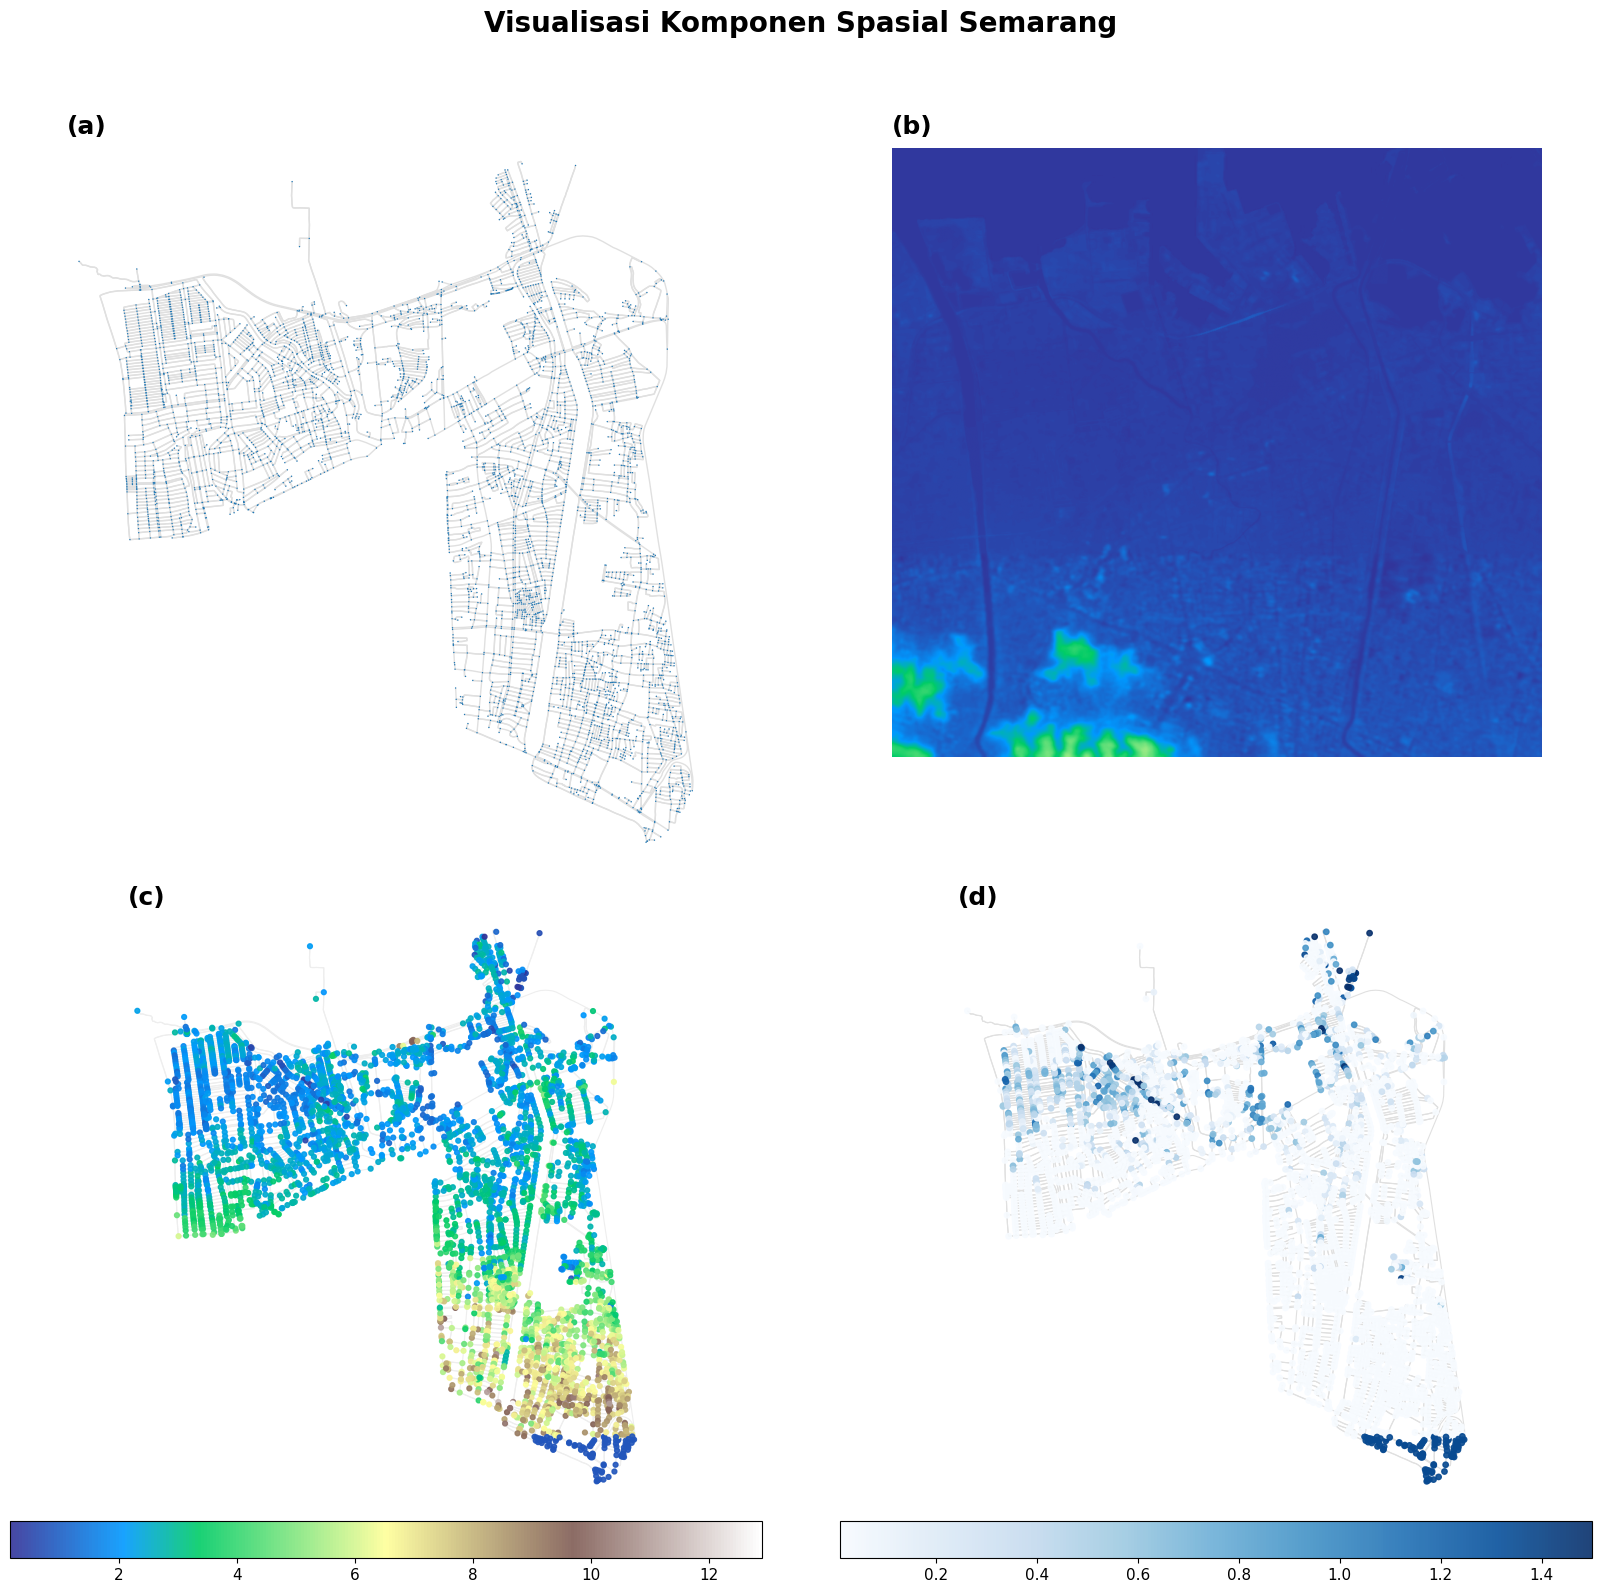

[PROSES SELESAI: 'Figure_3_visualisasi_komponen_spasial_semarang.png' BERHASIL DISIMPAN]


In [4]:
# =====================================================================
# INTERFACES & LIBRARIES LOAD (JALANKAN PADA NOTEBOOK BARU)
# =====================================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import osmnx as ox
import rasterio

print("============================================================")
print(" 1. CONFIGURATION & PATH SETUP                              ")
print("============================================================")

# Sesuaikan nama file dan lokasi folder penyimpanan Anda di sini
path_demnas = "/content/drive/MyDrive/Kuliah/Proyek ASA/04_Notebook/dataset/DEMNAS_1409-22_v1.0.tif"  # Nama file raster DEMNAS Anda
path_csv_pasang = "/content/drive/MyDrive/Kuliah/Proyek ASA/04_Notebook/dataset/chart_data.csv"  # Nama file CSV pasang surut BMKG

# Konfigurasi Batas Kecepatan Global (Sesuai Bab III)
GLOBAL_CONFIG = {
    "MOBIL_KECEPATAN_NORMAL_MPS": 8.33,   # 30 km/jam
    "WAKTU_BERANGKAT_MENIT": 60           # Menit awal keberangkatan
}

print(f" -> Path DEMNAS : {path_demnas}")
print(f" -> Path CSV    : {path_csv_pasang}")
print("-" * 70)

print(" 2. SPATIAL GRAPH ACQUISITION (OSMNX SCRAPING)              ")
print("============================================================")
tiga_kecamatan = [
    "Semarang Utara, Semarang, Central Java, Indonesia",
    "Semarang Timur, Central Java, Indonesia",
    "Gayamsari, Semarang, Central Java, Indonesia"
]

print(" Mengunduh topologi jaringan jalan raya untuk 3 kecamatan...")
G_raw = ox.graph_from_place(tiga_kecamatan, network_type='drive')
print(f" -> Graf Berhasil Diunduh. Nodes: {len(G_raw.nodes)}, Edges: {len(G_raw.edges)}")
print("-" * 70)

print(" 3. SPATIAL OVERLAY JOIN (DEMNAS SAMPLING)                  ")
print("============================================================")
# Melakukan overlay spatial data dari model raster ke komponen simpul graf
if os.path.exists(path_demnas):
    print(" Berkas DEMNAS ditemukan. Memulai ekstraksi datum vertikal EGM2008...")
    with rasterio.open(path_demnas) as dem_data:
        for node_id, data in G_raw.nodes(data=True):
            lon, lat = data['x'], data['y']
            raster_sample = dem_data.sample([(lon, lat)])
            val_elevasi = next(raster_sample)[0]

            # Filter proteksi jikalau koordinat berada di luar jangkauan piksel data raster
            if np.isnan(val_elevasi) or val_elevasi < -10.0 or val_elevasi > 150.0:
                G_raw.nodes[node_id]['elevation'] = 0.8  # Default elevasi Semarang Utara rawan rob
            else:
                G_raw.nodes[node_id]['elevation'] = float(val_elevasi)
    print(" -> Proses Spatial Point Join sukses disuntikkan ke seluruh Nodes.")
else:
    print(" [!] WARNING: File DEMNAS tidak ditemukan di direktori lokal.")
    print("      Menggunakan mode fallback simulasi tinggi seragam 0.8 meter.")
    for node_id in G_raw.nodes:
        G_raw.nodes[node_id]['elevation'] = 0.8

print("-" * 70)
print(" Proyeksikan Graf Transportasi ke Satuan Meter (UTM Zone 49S)...")
G = ox.project_graph(G_raw)
print("-" * 70)

print(" 4. TEMPORAL DATA LOAD (BMKG MARITIM CSV DISKRET)            ")
print("============================================================")
# Memuat data runtun waktu pasang surut diskret per interval 10 menit
if os.path.exists(path_csv_pasang):
    df_pasang = pd.read_csv(path_csv_pasang)
    df_pasang['menit_simulasi'] = np.arange(len(df_pasang)) * 10
    dict_pasang_est = pd.Series(df_pasang.EST.values, index=df_pasang.menit_simulasi).to_dict()
    print(" [STATUS: SUCCESS] Data runtun waktu pasang surut BMKG berhasil diarsip.")
else:
    print(" [!] WARNING: File CSV Pasang Surut tidak ditemukan.")
    print("      Menggunakan database dummy pasang naik statis puncak 1.56 meter.")
    dict_pasang_est = {0: 1.54, 10: 1.54, 20: 1.55, 30: 1.55, 40: 1.56, 50: 1.57}

print("-" * 70)

# =====================================================================
# CORE IMPLEMENTATION FUNCTION FOR GEOSPATIAL ANALYSIS
# =====================================================================
def hitung_kedalaman_rob_node(node_id, t_simulasi, graf_vektor):
    """Fungsi pembantu untuk mengukur ketinggian air di atas aspal jalan"""
    # Cari indeks batas atas kelipatan 10 menit diskret terdekat
    t_key = int(np.floor(t_simulasi / 10) * 10)
    tinggi_air_laut = dict_pasang_est.get(t_key, max(dict_pasang_est.values()))

    elevasi_tanah = graf_vektor.nodes[node_id].get('elevation', 0.8)
    kedalaman_genangan = tinggi_air_laut - elevasi_tanah
    return max(0.0, kedalaman_genangan)

print(" 5. GENERATOR RENDER CORES (FIGURE 3 PRODUCTION)             ")
print("============================================================")

# Extract koordinat pasca proyeksi UTM (meter)
node_utm_x = [G.nodes[node]['x'] for node in G.nodes]
node_utm_y = [G.nodes[node]['y'] for node in G.nodes]
node_elevations = [G.nodes[node]['elevation'] for node in G.nodes]

# Cari puncak pasang pasut tertinggi pada kolom EST
menit_puncak_est = max(dict_pasang_est.keys(), key=lambda k: dict_pasang_est[k])
tinggi_puncak_est = dict_pasang_est[menit_puncak_est]
node_water_depths = [hitung_kedalaman_rob_node(node, menit_puncak_est, G) for node in G.nodes]

# Setup Kanvas Gambar 2x2 Jurnal Internasional
fig3, axes3 = plt.subplots(2, 2, figsize=(18, 16))
fig3.suptitle('Visualisasi Komponen Spasial Semarang', fontsize=20, fontweight='bold', y=1.02) # Added main title
ax1, ax2, ax3, ax4 = axes3.flatten()

# --- SUB-PLOT 3(a): GRAF VEKTOR JALAN MURNI ---
ax1.set_title("(a)", fontsize=18, fontweight='bold', loc='left', pad=10)
ox.plot_graph(G, ax=ax1, node_size=1, node_color='#1f77b4', edge_color='#e0e0e0', bgcolor='white', show=False, close=False)

# --- SUB-PLOT 3(b): RASTER GRID CONTOUR DEMNAS ---
ax2.set_title("(b)", fontsize=18, fontweight='bold', loc='left', pad=10)
if os.path.exists(path_demnas):
    try:
        with rasterio.open(path_demnas) as dem_raster:
            node_lons = [G_raw.nodes[node]['x'] for node in G_raw.nodes]
            node_lats = [G_raw.nodes[node]['y'] for node in G_raw.nodes]

            from rasterio.plot import show as rshow
            rshow(dem_raster, ax=ax2, cmap='terrain', title=False)
            ax2.set_xlim(min(node_lons) - 0.005, max(node_lons) + 0.005)
            ax2.set_ylim(min(node_lats) - 0.005, max(node_lats) + 0.005)
    except Exception as e:
        ax2.text(0.5, 0.5, f"Error Render Raster:\n{str(e)}", ha='center', va='center', color='red', transform=ax2.transAxes)
else:
    ax2.text(0.5, 0.5, "File Raster DEMNAS Tidak Tersedia\n(Mode Fallback Aktif)", ha='center', va='center', fontsize=12, color='red', transform=ax2.transAxes)

# --- SUB-PLOT 3(c): OVERLAY GRAPH DENGAN HEATMAP ELEVASI LAND ---
ax3.set_title("(c)", fontsize=18, fontweight='bold', loc='left', pad=10)
ox.plot_graph(G, ax=ax3, node_size=0, edge_color='#eeeeee', edge_linewidth=0.8, bgcolor='white', show=False, close=False)
sc3 = ax3.scatter(node_utm_x, node_utm_y, c=node_elevations, cmap='terrain', s=12, alpha=0.9, zorder=3)
cbar3 = fig3.colorbar(sc3, ax=ax3, orientation='horizontal', pad=0.04, shrink=0.8)
cbar3.ax.tick_params(labelsize=11)

# --- SUB-PLOT 3(d): OVERLAY GRAPH GENANGAN ROB PUNCAK PASANG ---
ax4.set_title("(d)", fontsize=18, fontweight='bold', loc='left', pad=10)
ox.plot_graph(G, ax=ax4, node_size=0, edge_color='#e0e0e0', edge_linewidth=0.8, bgcolor='white', show=False, close=False)
sc4 = ax4.scatter(node_utm_x, node_utm_y, c=node_water_depths, cmap='Blues', s=15, alpha=0.9, vmin=0.01, vmax=1.5, zorder=3)
cbar4 = fig3.colorbar(sc4, ax=ax4, orientation='horizontal', pad=0.04, shrink=0.8)
cbar4.ax.tick_params(labelsize=11)

# Hilangkan frame sumbu luar untuk estetika visual spasial
for ax in [ax1, ax2, ax3, ax4]:
    ax.set_axis_off()

plt.tight_layout()
fig3.savefig('Figure_3_visualisasi_komponen_spasial_semarang.png', dpi=300, bbox_inches='tight')
plt.show()

print("============================================================")
print("[PROSES SELESAI: 'Figure_3_visualisasi_komponen_spasial_semarang.png' BERHASIL DISIMPAN]")
print("============================================================")

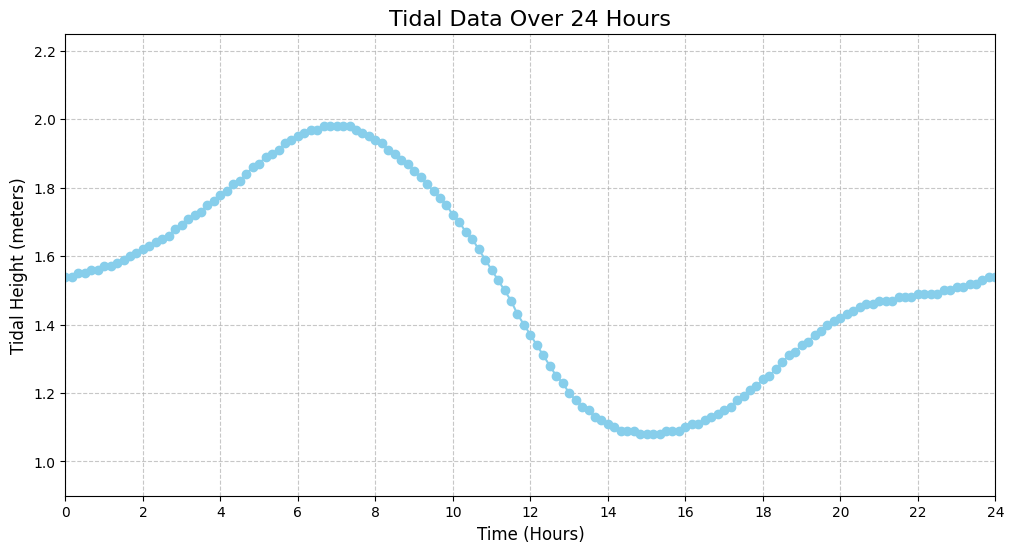

[PROSES SELESAI: 'tidal_data_24_hours.png' BERHASIL DISIMPAN]


In [5]:
import matplotlib.pyplot as plt

# Extract minutes and tidal values from the dictionary
minutes = list(dict_pasang_est.keys())
tidal_values = list(dict_pasang_est.values())

# Convert minutes to hours for plotting
hours = [m / 60 for m in minutes]

# Create the plot
plt.figure(figsize=(12, 6))
plt.plot(hours, tidal_values, marker='o', linestyle='-', color='skyblue')

# Add title and labels
plt.title('Tidal Data Over 24 Hours', fontsize=16)
plt.xlabel('Time (Hours)', fontsize=12)
plt.ylabel('Tidal Height (meters)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(range(0, 25, 2)) # Show ticks every 2 hours
plt.xlim(0, 24) # Ensure x-axis covers 24 hours
plt.ylim(min(tidal_values) - 0.1, max(tidal_values) + 0.1) # Adjust y-axis limits dynamically

# Save the figure
plt.savefig('tidal_data_24_hours.png', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()

print("===========================================================")
print("[PROSES SELESAI: 'tidal_data_24_hours.png' BERHASIL DISIMPAN]")
print("===========================================================")